In [1]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

np.random.seed(1)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

In [2]:
df_ = pd.read_csv("AirlineTweets.csv", encoding="ISO-8859-1")

In [3]:
df_.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:
df = df_[['airline_sentiment', 'text']].copy()

In [5]:
df.head()

,airline_sentiment,text
0,neutral,@VirginAmerica What @dhepburn said.
1,positive,@VirginAmerica plus you've added commercials t...
2,neutral,@VirginAmerica I didn't today... Must mean I n...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...


<Axes: >

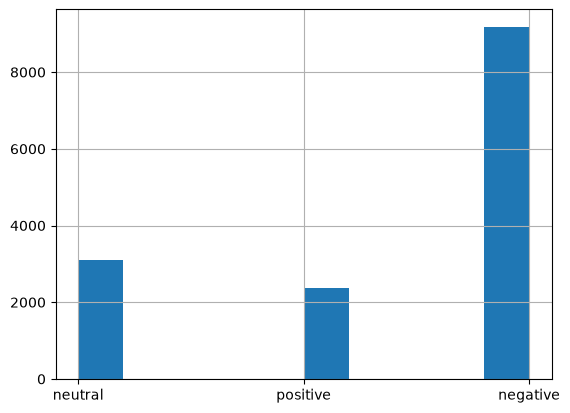

In [6]:
df['airline_sentiment'].hist()

In [7]:
target_map = {'positive': 1, 'negative': 0, 'neutral': 2}
df['target'] = df['airline_sentiment'].map(target_map)

In [8]:
df.head()

,airline_sentiment,text,target
0,neutral,@VirginAmerica What @dhepburn said.,2
1,positive,@VirginAmerica plus you've added commercials t...,1
2,neutral,@VirginAmerica I didn't today... Must mean I n...,2
3,negative,@VirginAmerica it's really aggressive to blast...,0
4,negative,@VirginAmerica and it's a really big bad thing...,0


In [9]:
df_train, df_test = train_test_split(df)

In [10]:
df_train.head()

,airline_sentiment,text,target
1041,negative,@united Change made in just over 3 hours. For ...,0
1989,negative,@united The engineer that designed the 787 doo...,0
14309,negative,"@AmericanAir 11 out of 11 delayed flights, you...",0
1711,negative,@united ouch not fair,0
11542,negative,@USAirways stuck in cae need reFlight Booking ...,0


In [11]:
vectorizer = TfidfVectorizer(max_features=2000)

X_train = vectorizer.fit_transform(df_train['text'])

X_train

X_test = vectorizer.transform(df_test['text'])

Y_train = df_train['target']
Y_test = df_test['target']

In [12]:
model = LogisticRegression(max_iter=500)
model.fit(X_train, Y_train)

print("Train acc:", model.score(X_train, Y_train))
print("Test acc:", model.score(X_test, Y_test))

Train acc: 0.8543715846994535
Test acc: 0.7975409836065573


In [13]:
Pr_train = model.predict_proba(X_train)  # [:, 1]
Pr_test = model.predict_proba(X_test)    # [:, 1]

print("Train AUC:", roc_auc_score(Y_train, Pr_train, multi_class='ovo'))
print("Test AUC:", roc_auc_score(Y_test, Pr_test, multi_class='ovo'))

Train AUC: 0.9426675324581831
Test AUC: 0.8952526482425792


In [14]:
P_train = model.predict(X_train)
P_test = model.predict(X_test)

In [15]:
cm = confusion_matrix(Y_train, P_train, normalize='true')
cm

array([[0.96471613, 0.00827646, 0.02700741],
       [0.19852941, 0.70079186, 0.10067873],
       [0.30322581, 0.05247312, 0.64430108]])

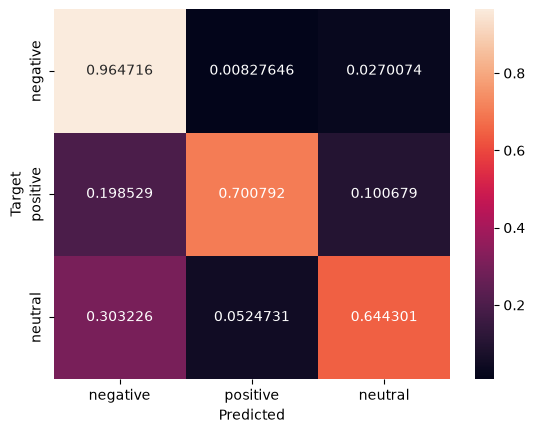

In [16]:
# Scikit-Learn is transitioning to V1 but it's not available on Colab
# The changes modify how confusion matrices are plotted
def plot_cm(cm):
  classes = ['negative', 'positive', 'neutral']
  df_cm = pd.DataFrame(cm, index=classes, columns=classes)
  ax = sn.heatmap(df_cm, annot=True, fmt='g')
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Target")

plot_cm(cm)

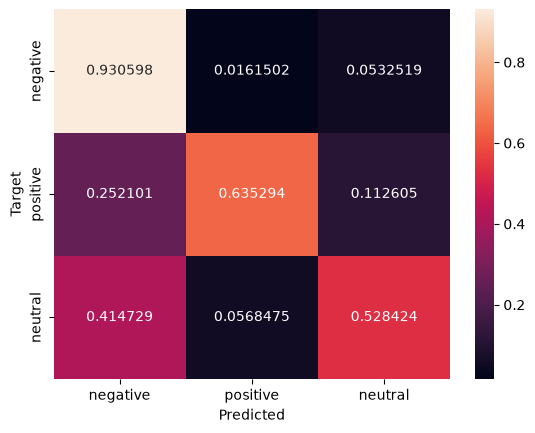

In [17]:
cm_test = confusion_matrix(Y_test, P_test, normalize='true')
plot_cm(cm_test)

## Binary Labels & Model Interpretation

In [18]:
binary_target_list = [target_map['positive'], target_map['negative']]

df_b_train = df_train[df_train['target'].isin(binary_target_list)]
df_b_test = df_test[df_test['target'].isin(binary_target_list)]

In [19]:
df_b_train.head()

,airline_sentiment,text,target
1041,negative,@united Change made in just over 3 hours. For ...,0
1989,negative,@united The engineer that designed the 787 doo...,0
14309,negative,"@AmericanAir 11 out of 11 delayed flights, you...",0
1711,negative,@united ouch not fair,0
11542,negative,@USAirways stuck in cae need reFlight Booking ...,0


In [20]:
X_train = vectorizer.fit_transform(df_b_train['text'])
X_test = vectorizer.transform(df_b_test['text'])

In [21]:
Y_train = df_b_train['target']
Y_test = df_b_test['target']

In [22]:
model = LogisticRegression(max_iter=500)
model.fit(X_train, Y_train)

print("Train acc:", model.score(X_train, Y_train))
print("Test acc:", model.score(X_test, Y_test))

Train acc: 0.9283651068746389
Test acc: 0.9144144144144144


In [23]:
Pr_train = model.predict_proba(X_train)[:, 1]
Pr_test = model.predict_proba(X_test)[:, 1]

print("Train AUC:", roc_auc_score(Y_train, Pr_train))
print("Test AUC:", roc_auc_score(Y_test, Pr_test))

Train AUC: 0.978925390285455
Test AUC: 0.9534616640196016


In [24]:
model.coef_

array([[-0.23968913, -0.13595781, -0.33365708, ...,  0.01095185,
        -0.5764017 ,  0.6781501 ]], shape=(1, 2000))

(array([  2.,   0.,   2.,   3.,   3.,  12.,  27.,  56., 194., 810., 530.,
        207.,  85.,  41.,  10.,   3.,   2.,   5.,   1.,   1.,   2.,   1.,
          1.,   0.,   0.,   0.,   0.,   0.,   0.,   2.]),
 array([-4.14821479, -3.74208715, -3.33595951, -2.92983187, -2.52370423,
        -2.11757659, -1.71144895, -1.30532131, -0.89919367, -0.49306603,
        -0.08693839,  0.31918925,  0.7253169 ,  1.13144454,  1.53757218,
         1.94369982,  2.34982746,  2.7559551 ,  3.16208274,  3.56821038,
         3.97433802,  4.38046566,  4.7865933 ,  5.19272094,  5.59884858,
         6.00497622,  6.41110386,  6.8172315 ,  7.22335914,  7.62948678,
         8.03561443]),
 <BarContainer object of 30 artists>)

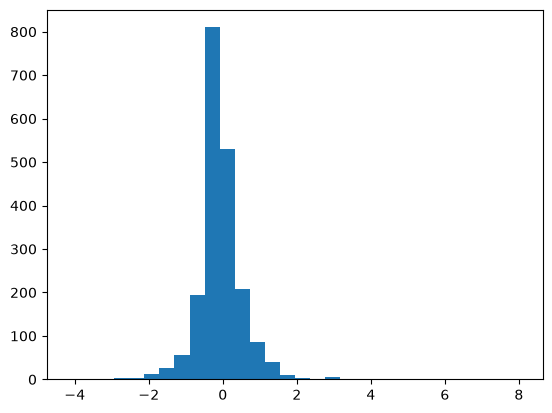

In [25]:
plt.hist(model.coef_[0], bins=30)

In [26]:
word_index_map = vectorizer.vocabulary_
word_index_map

{'united': np.int64(1842),
 'change': np.int64(339),
 'made': np.int64(1092),
 'in': np.int64(938),
 'just': np.int64(993),
 'over': np.int64(1272),
 'hours': np.int64(903),
 'for': np.int64(748),
 'something': np.int64(1622),
 'that': np.int64(1729),
 'should': np.int64(1577),
 'have': np.int64(854),
 'taken': np.int64(1703),
 'seconds': np.int64(1542),
 'online': np.int64(1247),
 'am': np.int64(136),
 'not': np.int64(1214),
 'loved': np.int64(1080),
 'the': np.int64(1731),
 'agent': np.int64(109),
 'though': np.int64(1747),
 'door': np.int64(570),
 'to': np.int64(1768),
 'half': np.int64(832),
 'into': np.int64(964),
 'plane': np.int64(1333),
 'seat': np.int64(1536),
 'be': np.int64(232),
 'forced': np.int64(749),
 'always': np.int64(135),
 'sit': np.int64(1593),
 'here': np.int64(875),
 'americanair': np.int64(140),
 '11': np.int64(6),
 'out': np.int64(1267),
 'of': np.int64(1228),
 'delayed': np.int64(499),
 'flights': np.int64(730),
 'you': np.int64(1989),
 'suck': np.int64(1676),

In [27]:
# let's look at the weights for each word
# try it with different threshold values!
threshold = 2

print("Most positive words:")
for word, index in word_index_map.items():
    weight = model.coef_[0][index]
    if weight > threshold:
        print(word, weight)

Most positive words:
southwestair 2.8657159794280216
thank 7.93811489944546
great 5.085746506306697
best 3.654611168330192
virginamerica 3.057026327666451
thx 2.8549802596826632
jetblue 2.95169481876463
good 3.2806893592646986
thanks 8.03561442536915
love 4.4113610338361156
appreciate 2.9878950053324003
awesome 4.099127628833746
cool 2.147753692922029
kudos 2.6216376693840293
amazing 4.297860562700398
worries 2.6572260909576797
wonderful 2.0417391645610894


In [28]:
print("Most negative words:")
for word, index in word_index_map.items():
    weight = model.coef_[0][index]
    if weight < -threshold:
        print(word, weight)

Most negative words:
hours -3.1500205358641713
not -4.148214791556908
delayed -2.7188983318145192
hour -2.0268387070174603
but -2.2201391248930302
cancelled -2.640450447127755
nothing -2.0809034255345225
no -3.8639409268319884
worst -3.204811167987118
hold -2.736401951267504
why -2.1817950404408384
doesn -2.0241104995356025
luggage -2.18984466146916


In [29]:
# Exercise: print the most-wrong tweets for both classes
# i.e. find a negative review where p(y = 1 | x) is closest to 1
#      find a positive review where p(y = 1 | x) is closest to 0

# Exercise: set class_weight='balanced'

In [30]:
import numpy as np

# 1. Find the most-wrong NEGATIVE tweet
# Create a boolean mask for actual negative tweets (0)
neg_mask = (Y_test.values == 0)
neg_probs = Pr_test[neg_mask] # Filter probabilities to only include negative tweets

# Find the index of the highest probability among the negative tweets
local_idx = np.argmax(neg_probs) 
# Map it back to the original index in the test set
original_idx = np.where(neg_mask)[0][local_idx] 

print("--- Most-wrong NEGATIVE tweet ---")
print(f"Predicted Probability of Positive: {Pr_test[original_idx]:.4f}")
print(f"Actual Sentiment: {df_b_test.iloc[original_idx]['airline_sentiment']}")
print(f"Tweet Text: {df_b_test.iloc[original_idx]['text']}\n")


# 2. Find the most-wrong POSITIVE tweet
# Create a boolean mask for actual positive tweets (1)
pos_mask = (Y_test.values == 1)
pos_probs = Pr_test[pos_mask]

# Find the index of the lowest probability among the positive tweets
local_idx = np.argmin(pos_probs)
# Map it back to the original index in the test set
original_idx = np.where(pos_mask)[0][local_idx]

print("--- Most-wrong POSITIVE tweet ---")
print(f"Predicted Probability of Positive: {Pr_test[original_idx]:.4f}")
print(f"Actual Sentiment: {df_b_test.iloc[original_idx]['airline_sentiment']}")
print(f"Tweet Text: {df_b_test.iloc[original_idx]['text']}")

--- Most-wrong NEGATIVE tweet ---
Predicted Probability of Positive: 0.9651
Actual Sentiment: negative
Tweet Text: @SouthwestAir oh, ok!  all good!  looking forward to escaping the cold for a bit!  thanks!

--- Most-wrong POSITIVE tweet ---
Predicted Probability of Positive: 0.0213
Actual Sentiment: positive
Tweet Text: @JetBlue Not trying to make you look bad, on your website it says: "Due to weather in the Charleston, NC" Its actually in SC, not NC


In [31]:
# Let's first check if our data is actually imbalanced
print("Class distribution in training set:")
print(Y_train.value_counts())
print("-" * 40)

# Train a new model with balanced class weights
model_balanced = LogisticRegression(max_iter=500, class_weight='balanced')
model_balanced.fit(X_train, Y_train)

# Get new probabilities
Pr_test_bal = model_balanced.predict_proba(X_test)[:, 1]

# Compare the metrics
print("Original Model Test Accuracy:  ", model.score(X_test, Y_test))
print("Balanced Model Test Accuracy:  ", model_balanced.score(X_test, Y_test))
print("-" * 40)
print("Original Model Test AUC:       ", roc_auc_score(Y_test, Pr_test))
print("Balanced Model Test AUC:       ", roc_auc_score(Y_test, Pr_test_bal))

Class distribution in training set:
target
0    6887
1    1768
Name: count, dtype: int64
----------------------------------------
Original Model Test Accuracy:   0.9144144144144144
Balanced Model Test Accuracy:   0.9085239085239085
----------------------------------------
Original Model Test AUC:        0.9534616640196016
Balanced Model Test AUC:        0.9545026391176288


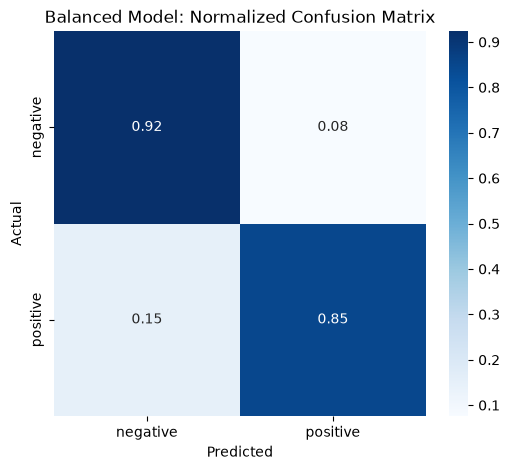

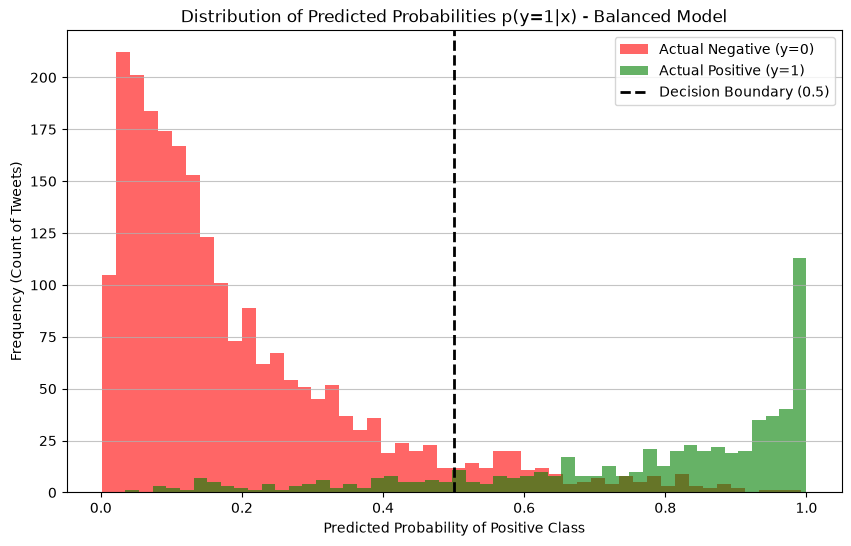

In [32]:
import matplotlib.pyplot as plt
import seaborn as sn
import pandas as pd
from sklearn.metrics import confusion_matrix

# ==========================================
# 1. Train the Balanced Model
# ==========================================
model_balanced = LogisticRegression(max_iter=500, class_weight='balanced')
model_balanced.fit(X_train, Y_train)

# Get predictions and probabilities for the test set
P_test_bal = model_balanced.predict(X_test)
Pr_test_bal = model_balanced.predict_proba(X_test)[:, 1] # Probability of positive class

# ==========================================
# 2. Plot the Confusion Matrix
# ==========================================
def plot_cm_binary(cm, title):
    # For the binary model, our classes are 'negative' (0) and 'positive' (1)
    classes = ['negative', 'positive']
    df_cm = pd.DataFrame(cm, index=classes, columns=classes)
    
    plt.figure(figsize=(6, 5))
    ax = sn.heatmap(df_cm, annot=True, fmt='.2f', cmap='Blues')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    plt.title(title)
    plt.show()

# Calculate and plot the normalized confusion matrix
cm_test_bal = confusion_matrix(Y_test, P_test_bal, normalize='true')
plot_cm_binary(cm_test_bal, "Balanced Model: Normalized Confusion Matrix")

# ==========================================
# 3. Plot the Probability Distribution
# ==========================================
plt.figure(figsize=(10, 6))

# Plot histogram for actual negative tweets (y=0)
plt.hist(Pr_test_bal[Y_test == 0], bins=50, alpha=0.6, label='Actual Negative (y=0)', color='red')

# Plot histogram for actual positive tweets (y=1)
plt.hist(Pr_test_bal[Y_test == 1], bins=50, alpha=0.6, label='Actual Positive (y=1)', color='green')

# Add a vertical line at the 0.5 decision boundary
plt.axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Decision Boundary (0.5)')

plt.title('Distribution of Predicted Probabilities p(y=1|x) - Balanced Model')
plt.xlabel('Predicted Probability of Positive Class')
plt.ylabel('Frequency (Count of Tweets)')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()